# Обучение U-Net для восстановления тусклых документов

Вход — испорченный RGB-снимок, цель — соответствующий читаемый исходник.
Модель предсказывает поправку: `restored = degraded + correction`.
RF-DETR здесь не обучается. Разметка строк для обучения восстановления не нужна.

**Локально:** открой `.ipynb` в корне проекта и выбери Python из `.venv`.
**Colab:** включи GPU, загрузи `restoration_training_bundle.zip` в `/content`
и выполняй ячейки сверху вниз. Архив распакуется автоматически.

В исходных данных 35 читаемых и 15 реально тусклых снимков. Реальные тусклые
снимки не участвуют в обучении и в расчёте парных метрик. Параметры синтетики
пока эвристические, не откалиброваны по реальным документам.

Связи между всеми грамотами пока неизвестны. Файл `document_groups.csv`
позволяет заполнить `document_id`. Пока он заполнен не полностью,
разбиение помечается как предварительное: независимость по грамотам не доказана.



In [1]:
# Если пакетов нет, установи их в среду ядра и перезапусти ядро:
# %pip install torch numpy pillow opencv-python matplotlib tqdm

import contextlib
import csv
from dataclasses import asdict, dataclass
from datetime import datetime
import hashlib
import importlib.metadata
import json
import math
import os
from pathlib import Path
import random
import re
import zipfile
from zoneinfo import ZoneInfo

import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm



/Users/atweshka/statita/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Настройки

Для первого запуска оставь значения по умолчанию. При нехватке видеопамяти
уменьши `BATCH_SIZE` до 1–2 или `PATCH_SIZE` до 256. Страницы не уменьшаются:
обучение идёт на фрагментах исходного разрешения.

`SMOKE_TEST=True` проверяет весь путь коротким запуском маленькой модели.
Это техническая проверка, а не обучение полезных весов.
Для продолжения укажи `RESUME_FROM` — путь к `last.pt` своего запуска.



In [2]:
SMOKE_TEST = os.environ.get("RESTORATION_SMOKE_TEST", "0") == "1"
DATA_DIR_OVERRIDE = os.environ.get("RESTORATION_DATA_DIR", "")
RUN_DIR_OVERRIDE = os.environ.get("RESTORATION_RUN_DIR", "")
RESUME_FROM = os.environ.get("RESTORATION_RESUME_FROM") or None  # например: "/content/restoration_runs/unet_.../last.pt"
DEVICE_OVERRIDE = os.environ.get("RESTORATION_DEVICE", "auto")  # auto / cuda / mps / cpu

SEED = 42
PATCH_SIZE = 512 if not SMOKE_TEST else 64
BASE_CHANNELS = 32 if not SMOKE_TEST else 4
BATCH_SIZE = 4 if not SMOKE_TEST else 1
EPOCHS = 40 if not SMOKE_TEST else 1
PATCHES_PER_PAGE = 16 if not SMOKE_TEST else 1
EVAL_CROPS_PER_PAGE = 4 if not SMOKE_TEST else 1
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
EARLY_STOPPING = 8
IDENTITY_PROBABILITY = 0.10  # иногда просим сохранить уже читаемый снимок
VAL_FRACTION = 0.15
TEST_FRACTION = 0.15
NUM_WORKERS = 0  # удобно для ноутбука и кэша; не увеличивать без изменения загрузчика
TILE_SIZE = 512 if not SMOKE_TEST else 64
TILE_OVERLAP = 64 if not SMOKE_TEST else 16
TILE_BATCH_SIZE = 4 if not SMOKE_TEST else 1
RUN_REAL_PREVIEW = True

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
cv2.setNumThreads(1)
torch.set_num_threads(4)
if DEVICE_OVERRIDE != "auto":
    DEVICE = torch.device(DEVICE_OVERRIDE)
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
USE_AMP = DEVICE.type == "cuda"


def find_data_directory():
    if DATA_DIR_OVERRIDE:
        result = Path(DATA_DIR_OVERRIDE).expanduser().resolve()
        if not (result / "manifest.csv").is_file():
            raise FileNotFoundError(f"Не найден manifest.csv: {result}")
        return result
    roots = [Path.cwd(), Path.cwd().parent, Path("/content")]
    for root in roots:
        for candidate in (root / "restoration_dataset_50",
                          root / "restoration_training_data" / "restoration_dataset_50"):
            if (candidate / "manifest.csv").is_file():
                return candidate.resolve()
    for root in roots:
        bundle = root / "restoration_training_bundle.zip"
        if not bundle.is_file():
            continue
        destination = root / "restoration_training_data"
        destination.mkdir(exist_ok=True)
        with zipfile.ZipFile(bundle) as archive:
            for member in archive.infolist():
                target = (destination / member.filename).resolve()
                if not target.is_relative_to(destination.resolve()):
                    raise ValueError("Некорректный путь в архиве")
            archive.extractall(destination)
        candidate = destination / "restoration_dataset_50"
        if (candidate / "manifest.csv").is_file():
            return candidate.resolve()
    raise FileNotFoundError("Укажи DATA_DIR_OVERRIDE или загрузи restoration_training_bundle.zip")


DATA_DIR = find_data_directory()
if RESUME_FROM:
    RUN_DIR = Path(RESUME_FROM).expanduser().resolve().parent
elif RUN_DIR_OVERRIDE:
    RUN_DIR = Path(RUN_DIR_OVERRIDE).expanduser().resolve()
else:
    name = datetime.now(ZoneInfo("Europe/Moscow")).strftime("unet_%Y%m%d_%H%M%S")
    RUN_DIR = DATA_DIR.parent / "restoration_runs" / name
RUN_DIR.mkdir(parents=True, exist_ok=True)
for folder in ("cache/paper", "cache/fixed", "restored", "figures"):
    (RUN_DIR / folder).mkdir(parents=True, exist_ok=True)
print("Данные:", DATA_DIR)
print("Результаты:", RUN_DIR)
print("Устройство:", DEVICE, "| AMP:", USE_AMP, "| Smoke test:", SMOKE_TEST)



Данные: /Users/atweshka/statita/restoration_dataset_50
Результаты: /Users/atweshka/statita/restoration_runs/unet_20261018_174404
Устройство: mps | AMP: False | Smoke test: False


## 2. Генератор порчи

Следующая ячейка содержит тот же алгоритм, которым были подготовлены примеры.
Она включена в блокнот целиком: отдельный Python-модуль не требуется.
На обучении полная страница ухудшается заново каждую эпоху, затем из неё
вырезаются совпадающие фрагменты входа и цели. Это сохраняет масштаб эффектов.
Для валидации/теста используются фиксированные параметры и координаты фрагментов.



In [3]:
@dataclass(frozen=True)
class DegradationParameters:
    seed: int
    level: str
    severity: float
    ink_retention: float
    fade_variation: float
    blur_sigma_at_2048: float
    noise_sigma_255: float
    lighting_amplitude: float
    lighting_angle: float
    stain_count: int
    stain_amplitude: float
    fold_amplitude: float
    fold_position: float
    fold_width: float
    fold_angle: float
    bleed_strength: float
    bleed_shift_x: float
    bleed_shift_y: float
    bleed_blur_at_2048: float


def sample_parameters(seed: int, level: str = "random") -> DegradationParameters:
    """Sample parameters without changing NumPy's global random state."""
    rng = np.random.default_rng(seed)
    ranges = {"mild": (0.12, 0.28), "medium": (0.43, 0.59), "strong": (0.77, 0.92),
              "random": (0.08, 0.94)}
    if level not in ranges:
        raise ValueError(f"Unknown level: {level}")
    severity = float(rng.uniform(*ranges[level]))
    return DegradationParameters(
        seed=int(seed), level=level, severity=severity,
        ink_retention=1.0 - 0.91 * severity,
        fade_variation=float(rng.uniform(0.10, 0.22) * severity),
        blur_sigma_at_2048=float(rng.uniform(0.12, 0.25) + 0.80 * severity),
        noise_sigma_255=float(rng.uniform(0.30, 0.65) + 2.2 * severity),
        lighting_amplitude=float(rng.uniform(0.015, 0.055) * severity),
        lighting_angle=float(rng.uniform(-math.pi, math.pi)),
        stain_count=int(rng.integers(1, 4)),
        stain_amplitude=float(rng.uniform(0.025, 0.065) * severity),
        fold_amplitude=float(rng.uniform(0.035, 0.10) * severity),
        fold_position=float(rng.uniform(0.15, 0.85)),
        fold_width=float(rng.uniform(0.014, 0.035)),
        fold_angle=float(rng.uniform(-0.17, 0.17)),
        bleed_strength=float(rng.uniform(0.025, 0.085) * severity),
        bleed_shift_x=float(rng.uniform(-0.06, 0.06)),
        bleed_shift_y=float(rng.uniform(-0.13, 0.13)),
        bleed_blur_at_2048=float(rng.uniform(0.9, 1.8)),
    )


def read_rgb(path: Path) -> Image.Image:
    """Use this for targets too: manifest coordinates follow EXIF orientation."""
    with Image.open(path) as raw:
        return ImageOps.exif_transpose(raw).convert("RGB")


def _blur(array: np.ndarray, sigma: float) -> np.ndarray:
    if sigma <= 0:
        return array
    return cv2.GaussianBlur(array, (0, 0), sigmaX=sigma, sigmaY=sigma,
                            borderType=cv2.BORDER_REFLECT_101)


def estimate_paper(image: Image.Image) -> np.ndarray:
    """Approximate local paper RGB with closing; this is not a text annotation.

    Working at a bounded resolution makes the kernel relative to page size.
    Large seals and shadows are mostly retained; small dark strokes are filled.
    """
    rgb = np.asarray(image, dtype=np.uint8)
    h, w = rgb.shape[:2]
    scale = min(1.0, 1600.0 / max(h, w))
    small = cv2.resize(rgb, (max(1, round(w * scale)), max(1, round(h * scale))),
                       interpolation=cv2.INTER_AREA)
    kernel_size = max(3, round(max(small.shape[:2]) * 0.020)) | 1
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
    paper = cv2.morphologyEx(small, cv2.MORPH_CLOSE, kernel)
    paper = _blur(paper.astype(np.float32), 2.0)
    return cv2.resize(paper, (w, h), interpolation=cv2.INTER_LINEAR)


def _field(rng: np.random.Generator, h: int, w: int) -> np.ndarray:
    field = rng.uniform(-1, 1, (6, 6)).astype(np.float32)
    return np.clip(cv2.resize(field, (w, h), interpolation=cv2.INTER_CUBIC), -1, 1)


def degrade_document(
    image: Image.Image,
    parameters: DegradationParameters,
    *,
    paper: np.ndarray | None = None,
) -> Image.Image:
    """Return a new RGB image with unchanged text coordinates and pixel dimensions.

    Bleed-through uses a mirrored, shifted residual of this same page. This is a
    simple proxy for reverse-side text and introduces no other document's text.
    The input PIL image and an optional cached paper array are never modified.
    """
    rgb = image.convert("RGB")
    original = np.asarray(rgb, dtype=np.float32)
    h, w = original.shape[:2]
    if paper is None:
        paper = estimate_paper(rgb)
    if paper.shape != original.shape:
        raise ValueError("Paper estimate and image must have the same dimensions")
    p = parameters
    rng = np.random.default_rng(p.seed)
    scale = max(h, w) / 2048.0

    # Positive local difference contains predominantly dark strokes. A soft gate
    # avoids treating every small paper-texture fluctuation as handwriting.
    residual = np.maximum(paper - original, 0)
    residual_luma = residual @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    residual *= np.clip((residual_luma - 2.0) / 8.0, 0, 1)[..., None]
    retention = np.clip(p.ink_retention + p.fade_variation * _field(rng, h, w),
                        0.035, 1.0)
    out = original + (1.0 - retention[..., None]) * residual

    paper_luma = paper @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    on_paper = np.clip((paper_luma - 65) / 80, 0, 1)
    if p.bleed_strength > 0:
        ghost = _blur(np.ascontiguousarray(residual[:, ::-1]),
                      p.bleed_blur_at_2048 * scale)
        transform = np.float32([[1, 0, p.bleed_shift_x * w],
                               [0, 1, p.bleed_shift_y * h]])
        ghost = cv2.warpAffine(ghost, transform, (w, h), flags=cv2.INTER_LINEAR,
                               borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        out -= p.bleed_strength * ghost * on_paper[..., None]

    # Lighting and stains are smooth fields, not rectangles or pasted textures.
    field_scale = min(1.0, 600.0 / max(h, w))
    fh, fw = max(2, round(h * field_scale)), max(2, round(w * field_scale))
    yy, xx = np.mgrid[0:1:complex(fh), 0:1:complex(fw)].astype(np.float32)
    lighting = p.lighting_amplitude * (
        math.cos(p.lighting_angle) * (xx - 0.5)
        + math.sin(p.lighting_angle) * (yy - 0.5))
    stain = np.zeros((fh, fw), dtype=np.float32)
    for _ in range(p.stain_count):
        cx, cy = rng.uniform(0.08, 0.92, 2)
        sx, sy = rng.uniform(0.035, 0.13, 2)
        amplitude = p.stain_amplitude * rng.uniform(0.5, 1.0)
        stain += amplitude * np.exp(-0.5 * (((xx - cx) / sx) ** 2
                                          + ((yy - cy) / sy) ** 2))
    fold_distance = xx - p.fold_position + p.fold_angle * (yy - 0.5)
    fold = p.fold_amplitude * np.exp(-0.5 * (fold_distance / p.fold_width) ** 2)
    shade = cv2.resize(lighting - fold, (w, h), interpolation=cv2.INTER_LINEAR)
    stain = cv2.resize(stain, (w, h), interpolation=cv2.INTER_LINEAR)
    out *= 1.0 + (shade * on_paper)[..., None]
    for channel, tint in enumerate((0.70, 0.95, 1.20)):
        out[..., channel] *= 1.0 - np.minimum(stain * tint, 0.30) * on_paper

    out = _blur(out, p.blur_sigma_at_2048 * scale)
    if p.noise_sigma_255 > 0:
        noise = rng.standard_normal((h, w), dtype=np.float32) * p.noise_sigma_255
        out += noise[..., None]
    return Image.fromarray(np.rint(np.clip(out, 0, 255)).astype(np.uint8))




## 3. Данные и группы документов

Перед длительным обучением проверь `restoration_dataset_50/document_groups.csv`.
В `document_id` можно вписать идентификатор грамоты, общий для всех её страниц.
Уже известные дела, дополняющие ракурсы и совпадающие номера листов группируются
консервативно. Совпадающий номер листа может объединить разные документы;
такое разбиение всё равно остаётся предварительным до проверки происхождения.
Все синтетические версии страницы всегда следуют за её исходником.



In [4]:
def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def stable_seed(*parts):
    value = "|".join(map(str, parts)).encode("utf-8")
    return int.from_bytes(hashlib.sha256(value).digest()[:4], "little")


def save_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")


with (DATA_DIR / "manifest.csv").open(encoding="utf-8-sig", newline="") as stream:
    all_rows = list(csv.DictReader(stream))
clear_rows = [dict(r, path=str(DATA_DIR / r["dataset_path"])) for r in all_rows if r["category"] == "clear"]
assert len(clear_rows) >= 3
assert len({r["sha256"] for r in clear_rows}) == len(clear_rows)
for row in clear_rows:
    if file_sha256(row["path"]) != row["sha256"]:
        raise ValueError(f"Изменился исходник: {row['filename']}")

groups_path = DATA_DIR / "document_groups.csv"
if not groups_path.exists():
    group_rows = []
    for row in clear_rows:
        name = row["filename"].removeprefix("Train__")
        case = re.search(r"(?:Д\.|дело)\s*(\d+)", name, re.IGNORECASE)
        leaf = re.search(r"(?:лист\s*|л[._]\s*)(\d+)", name, re.IGNORECASE)
        group_rows.append(dict(page_id=row["id"], filename=row["filename"], document_id="",
                               archive_case=case.group(1) if case else "",
                               known_view_group=row["related_views_group"],
                               leaf_hint=leaf.group(1) if leaf else ""))
    with groups_path.open("w", encoding="utf-8-sig", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(group_rows[0]))
        writer.writeheader()
        writer.writerows(group_rows)
with groups_path.open(encoding="utf-8-sig", newline="") as stream:
    group_rows = list(csv.DictReader(stream))
group_by_id = {r["page_id"]: r for r in group_rows}
assert len(group_by_id) == len(group_rows), "Повторяется page_id в document_groups.csv"
assert {r["id"] for r in clear_rows} == set(group_by_id), "Таблица групп не соответствует набору"

parent = {r["id"]: r["id"] for r in clear_rows}


def find(key):
    while parent[key] != key:
        parent[key] = parent[parent[key]]
        key = parent[key]
    return key


def union(a, b):
    a, b = sorted((find(a), find(b)))
    parent[b] = a


for field in ("document_id", "archive_case", "known_view_group", "leaf_hint"):
    seen = {}
    for row in clear_rows:
        value = group_by_id[row["id"]].get(field, "").strip()
        if not value:
            continue
        if value in seen:
            a, b = group_by_id[seen[value]], group_by_id[row["id"]]
            # Different manually assigned documents may reuse the same leaf number.
            if field == "leaf_hint" and a["document_id"] and b["document_id"] and a["document_id"] != b["document_id"]:
                continue
            union(seen[value], row["id"])
        else:
            seen[value] = row["id"]
for row in clear_rows:
    row["group_id"] = find(row["id"])
    row["document_id"] = group_by_id[row["id"]]["document_id"].strip()
SPLIT_SCOPE = "user_assigned_documents" if all(r["document_id"] for r in clear_rows) else "provisional_known_links"
group_ids = sorted({r["group_id"] for r in clear_rows})
if len(group_ids) < 3:
    raise ValueError("Для трёх частей нужно не менее трёх независимых групп документов")
random.Random(SEED).shuffle(group_ids)
n_val = max(1, round(len(group_ids) * VAL_FRACTION))
n_test = max(1, round(len(group_ids) * TEST_FRACTION))
if n_val + n_test >= len(group_ids):
    raise ValueError("Уменьши VAL_FRACTION и TEST_FRACTION")
group_split = {g: "val" if i < n_val else "test" if i < n_val + n_test else "train"
               for i, g in enumerate(group_ids)}
for row in clear_rows:
    row["split"] = group_split[row["group_id"]]
splits = {split: [r for r in clear_rows if r["split"] == split] for split in ("train", "val", "test")}
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    assert not {r["group_id"] for r in splits[a]} & {r["group_id"] for r in splits[b]}
    assert not {r["sha256"] for r in splits[a]} & {r["sha256"] for r in splits[b]}
snapshot = [dict(page_id=r["id"], sha256=r["sha256"], group_id=r["group_id"],
                 document_id=r["document_id"], split=r["split"]) for r in sorted(clear_rows, key=lambda r: r["id"])]
SPLIT_FINGERPRINT = hashlib.sha256(json.dumps(snapshot, sort_keys=True).encode()).hexdigest()
split_file = RUN_DIR / "split.json"
if split_file.exists() and json.loads(split_file.read_text())["fingerprint"] != SPLIT_FINGERPRINT:
    raise ValueError("Разбиение изменилось: выбери новую папку запуска")
save_json(split_file, dict(scope=SPLIT_SCOPE, seed=SEED, fingerprint=SPLIT_FINGERPRINT, pages=snapshot))
with (RUN_DIR / "split_manifest.csv").open("w", encoding="utf-8-sig", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(snapshot[0]))
    writer.writeheader()
    writer.writerows(snapshot)
for split, rows in splits.items():
    print(f"{split}: {len(rows)} снимков, {len({r['group_id'] for r in rows})} групп")
print("Статус разбиения:", SPLIT_SCOPE)
print("Таблица для проверки:", groups_path)
if SMOKE_TEST:
    splits = {"train": splits["train"][:2], "val": splits["val"][:1], "test": splits["test"][:1]}
    print("Smoke test: используем только 2 train / 1 val / 1 test снимка")



train: 26 снимков, 16 групп
val: 5 снимков, 4 групп
test: 4 снимков, 4 групп
Статус разбиения: provisional_known_links
Таблица для проверки: /Users/atweshka/statita/restoration_dataset_50/document_groups.csv


## 4. Парные фрагменты

Чаще выбираются участки с фактурой/штрихами, чтобы обучение не состояло
преимущественно из пустой бумаги. Это эвристика выбора фрагментов, не разметка текста.
На обучении порядок страниц и порча меняются каждую эпоху. Загрузчик сохраняет
в памяти одну полную пару; обучение не загружает весь набор в RAM.
Валидация/тест используют по три фиксированных уровня порчи и одинаковые фрагменты.
Если существующие 105 пар доступны локально, берутся соответствующие файлы;
в Colab недостающие варианты создаются и кэшируются с фиксированными seed.



In [5]:
LEVELS = ("mild", "medium", "strong")
fixed_pairs = {}
pair_manifest = DATA_DIR / "synthetic_pairs" / "manifest.jsonl"
if pair_manifest.exists():
    for line in pair_manifest.read_text().splitlines():
        pair = json.loads(line)
        key = (pair["target_sha256"], pair["parameters"]["level"])
        fixed_pairs[key] = (DATA_DIR / "synthetic_pairs" / pair["input"], pair["input_sha256"], pair["parameters"])


def cached_paper(row, target):
    path = RUN_DIR / "cache/paper" / f"{row['sha256']}.png"
    if path.exists():
        with Image.open(path) as im:
            if im.size != target.size:
                raise ValueError("Не совпадает размер кэша бумаги")
            return np.array(im, dtype=np.float32)
    paper = estimate_paper(target)
    Image.fromarray(np.rint(np.clip(paper, 0, 255)).astype(np.uint8)).save(path)
    # Use the same quantized estimate on the first and subsequent visits.
    return np.rint(np.clip(paper, 0, 255)).astype(np.float32)


def fixed_pair(row, level):
    target = read_rgb(Path(row["path"]))
    existing = fixed_pairs.get((row["sha256"], level))
    if existing and existing[0].is_file():
        if file_sha256(existing[0]) != existing[1]:
            raise ValueError("Изменился сохранённый синтетический вход")
        degraded = read_rgb(existing[0])
    else:
        seed = existing[2]["seed"] if existing else stable_seed(SEED, row["sha256"], level, "fixed")
        path = RUN_DIR / "cache/fixed" / f"{row['sha256']}_{level}_{seed}.png"
        if path.exists():
            degraded = read_rgb(path)
        else:
            # Use the recorded parameters when only a thin manifest was uploaded.
            params = DegradationParameters(**existing[2]) if existing else sample_parameters(seed, level)
            paper = estimate_paper(target) if existing else cached_paper(row, target)
            degraded = degrade_document(target, params, paper=paper)
            degraded.save(path, compress_level=2)
    assert degraded.size == target.size
    return degraded, target


def pad_to_patch(image, size):
    arr = np.asarray(image)
    h, w = arr.shape[:2]
    if h < size or w < size:
        arr = np.pad(arr, ((0, max(0, size - h)), (0, max(0, size - w)), (0, 0)), mode="reflect")
    return Image.fromarray(arr)


def crop_box(target, size, rng, prefer_text=True):
    width, height = target.size
    candidates = []
    for _ in range(8 if prefer_text else 1):
        x = int(rng.integers(0, width - size + 1))
        y = int(rng.integers(0, height - size + 1))
        box = (x, y, x + size, y + size)
        gray = np.asarray(target.crop(box).convert("L").resize((64, 64)), dtype=np.float32)
        score = float(gray.std()) if float((gray < 60).mean()) < 0.25 and gray.mean() > 80 else -1.0
        candidates.append((score, box))
    return max(candidates, key=lambda item: item[0])[1]


def to_tensor(image):
    return torch.from_numpy(np.array(image, dtype=np.float32).transpose(2, 0, 1).copy()) / 255.0


class TrainPatches(Dataset):
    def __init__(self, rows):
        self.rows = rows
        self.epoch = 0
        self.order = list(range(len(rows)))
        self.cache_key = None
        self.cache = None

    def set_epoch(self, epoch):
        self.epoch = epoch
        self.order = list(range(len(self.rows)))
        random.Random(stable_seed(SEED, epoch, "order")).shuffle(self.order)
        self.cache_key, self.cache = None, None

    def __len__(self):
        return len(self.rows) * PATCHES_PER_PAGE

    def __getitem__(self, index):
        page_index = self.order[index // PATCHES_PER_PAGE]
        row = self.rows[page_index]
        key = (self.epoch, row["id"])
        if self.cache_key != key:
            self.cache = None
            target = read_rgb(Path(row["path"]))
            seed = stable_seed(SEED, self.epoch, row["sha256"], "train")
            if np.random.default_rng(stable_seed(seed, "identity")).random() < IDENTITY_PROBABILITY:
                degraded = target.copy()
            else:
                degraded = degrade_document(target, sample_parameters(seed, "random"), paper=cached_paper(row, target))
            self.cache = (pad_to_patch(degraded, PATCH_SIZE), pad_to_patch(target, PATCH_SIZE))
            self.cache_key = key
        degraded, target = self.cache
        rng = np.random.default_rng(stable_seed(SEED, self.epoch, index, "crop"))
        box = crop_box(target, PATCH_SIZE, rng, prefer_text=bool(rng.random() < 0.8))
        return to_tensor(degraded.crop(box)), to_tensor(target.crop(box))


class FixedPatches(Dataset):
    def __init__(self, rows):
        self.samples = [(row, level, crop) for row in rows for level in LEVELS
                        for crop in range(EVAL_CROPS_PER_PAGE)]
        self.cache_key, self.cache = None, None

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        row, level, crop = self.samples[index]
        key = (row["id"], level)
        if self.cache_key != key:
            self.cache = None
            degraded, target = fixed_pair(row, level)
            self.cache = (pad_to_patch(degraded, PATCH_SIZE), pad_to_patch(target, PATCH_SIZE))
            self.cache_key = key
        degraded, target = self.cache
        # Exactly the same coordinates are evaluated across severity levels.
        rng = np.random.default_rng(stable_seed(SEED, row["sha256"], crop, "eval_crop"))
        box = crop_box(target, PATCH_SIZE, rng)
        return to_tensor(degraded.crop(box)), to_tensor(target.crop(box))


train_data = TrainPatches(splits["train"])
val_data = FixedPatches(splits["val"])
test_data = FixedPatches(splits["test"])
loader_args = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
train_loader = DataLoader(train_data, shuffle=False, **loader_args)
val_loader = DataLoader(val_data, shuffle=False, **loader_args)
test_loader = DataLoader(test_data, shuffle=False, **loader_args)
print("Фрагментов за эпоху:", len(train_data), "| val:", len(val_data), "| test:", len(test_data))



Фрагментов за эпоху: 416 | val: 60 | test: 48


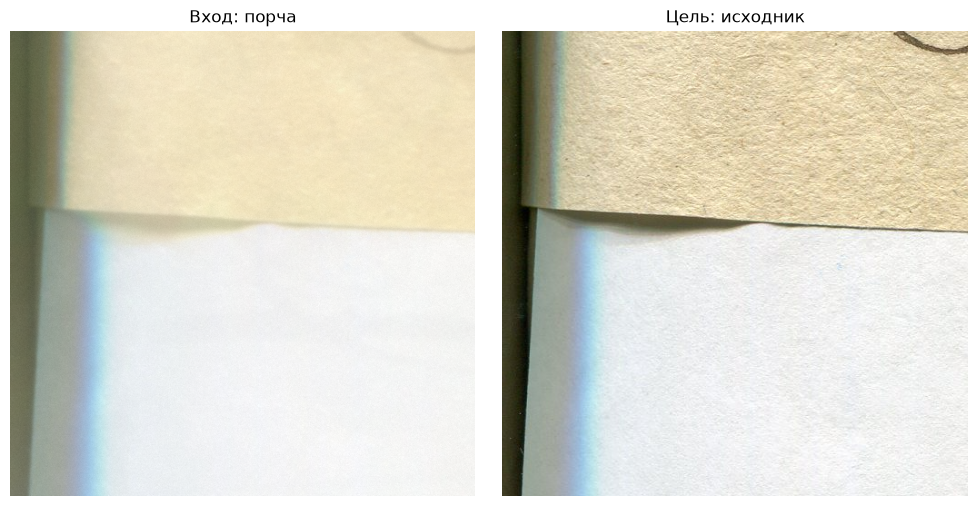

In [6]:
train_data.set_epoch(0)
sample_x, sample_y = train_data[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, tensor, title in zip(axes, (sample_x, sample_y), ("Вход: порча", "Цель: исходник")):
    ax.imshow(tensor.permute(1, 2, 0).numpy())
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
fig.savefig(RUN_DIR / "figures/training_pair.png", dpi=150)
plt.show()
plt.close(fig)
train_data.cache_key, train_data.cache = None, None



## 5. Residual U-Net

Четыре масштаба: 32 → 64 → 128 → 256 каналов; три уменьшения разрешения.
Skip connections передают детали между соответствующими уровнями.
Последняя свёртка инициализирована нулями: до обучения сеть возвращает вход.
Во время обучения выход не обрезается, чтобы сохранить градиент;
при оценке/экспорте он ограничивается диапазоном [0, 1].

Основа архитектуры: https://arxiv.org/abs/1505.04597



In [7]:
class DoubleConv(nn.Module):
    def __init__(self, incoming, outgoing):
        super().__init__()
        self.layers = nn.Sequential(nn.Conv2d(incoming, outgoing, 3, padding=1), nn.ReLU(inplace=True),
                                    nn.Conv2d(outgoing, outgoing, 3, padding=1), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.layers(x)


class ResidualUNet(nn.Module):
    def __init__(self, base_channels=32):
        super().__init__()
        b = base_channels
        self.enc1, self.enc2 = DoubleConv(3, b), DoubleConv(b, 2 * b)
        self.enc3, self.bottom = DoubleConv(2 * b, 4 * b), DoubleConv(4 * b, 8 * b)
        self.dec3, self.dec2 = DoubleConv(12 * b, 4 * b), DoubleConv(6 * b, 2 * b)
        self.dec1 = DoubleConv(3 * b, b)
        self.head = nn.Conv2d(b, 3, 1)
        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x):
        height, width = x.shape[-2:]
        padded = F.pad(x, (0, (-width) % 8, 0, (-height) % 8), mode="reflect")
        a = self.enc1(padded)
        b = self.enc2(F.max_pool2d(a, 2))
        c = self.enc3(F.max_pool2d(b, 2))
        d = self.bottom(F.max_pool2d(c, 2))
        d = self.dec3(torch.cat((F.interpolate(d, size=c.shape[-2:], mode="bilinear", align_corners=False), c), 1))
        d = self.dec2(torch.cat((F.interpolate(d, size=b.shape[-2:], mode="bilinear", align_corners=False), b), 1))
        d = self.dec1(torch.cat((F.interpolate(d, size=a.shape[-2:], mode="bilinear", align_corners=False), a), 1))
        return x + self.head(d)[..., :height, :width]


model = ResidualUNet(BASE_CHANNELS).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
print(f"Параметров модели: {sum(p.numel() for p in model.parameters()):,}")



Параметров модели: 1,946,947


## 6. Оценка и сохранение весов

L1 и PSNR считаются на фиксированных парных фрагментах. В таблице будут
показатели входа и результата: рост PSNR и уменьшение L1 означают приближение
к читаемому исходнику. Это не метрики детекции и не проверка правильности букв.

`best.pt` выбирается только по val L1. Test не используется для выбора эпохи.
Нулевая эпоха сохраняется как baseline: модель пока просто возвращает вход.
Веса загружаются через `torch.load(..., weights_only=True)`.



In [8]:
CONFIG = dict(seed=SEED, patch_size=PATCH_SIZE, base_channels=BASE_CHANNELS,
              batch_size=BATCH_SIZE, epochs=EPOCHS, patches_per_page=PATCHES_PER_PAGE,
              eval_crops_per_page=EVAL_CROPS_PER_PAGE, learning_rate=LEARNING_RATE,
              weight_decay=WEIGHT_DECAY, identity_probability=IDENTITY_PROBABILITY,
              split_scope=SPLIT_SCOPE, split_fingerprint=SPLIT_FINGERPRINT,
              smoke_test=SMOKE_TEST, device=str(DEVICE), amp=USE_AMP,
              generator_version=1, target_loading="EXIF transpose, RGB",
              versions={name: importlib.metadata.version(name) for name in ("torch", "numpy", "Pillow", "opencv-python")})


def amp_context():
    return torch.autocast("cuda", dtype=torch.float16) if USE_AMP else contextlib.nullcontext()


@torch.inference_mode()
def evaluate(network, loader):
    network.eval()
    totals = dict(input_abs=0.0, output_abs=0.0, input_sq=0.0, output_sq=0.0, pixels=0)
    for degraded, target in loader:
        degraded, target = degraded.to(DEVICE), target.to(DEVICE)
        with amp_context():
            restored = network(degraded).float().clamp(0, 1)
        before, after = degraded - target, restored - target
        totals["input_abs"] += before.abs().sum().item()
        totals["output_abs"] += after.abs().sum().item()
        totals["input_sq"] += before.square().sum().item()
        totals["output_sq"] += after.square().sum().item()
        totals["pixels"] += target.numel()
    n = totals["pixels"]
    return dict(input_l1=totals["input_abs"] / n, output_l1=totals["output_abs"] / n,
                input_psnr=-10 * math.log10(max(totals["input_sq"] / n, 1e-12)),
                output_psnr=-10 * math.log10(max(totals["output_sq"] / n, 1e-12)))


def save_checkpoint(path, epoch, best_l1, best_epoch, history):
    payload = dict(model=model.state_dict(), optimizer=optimizer.state_dict(),
                   scheduler=scheduler.state_dict(), scaler=scaler.state_dict(), epoch=epoch,
                   best_l1=best_l1, best_epoch=best_epoch, history=history,
                   config=CONFIG, split_fingerprint=SPLIT_FINGERPRINT,
                   architecture="ResidualUNet", base_channels=BASE_CHANNELS)
    temporary = Path(str(path) + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


history = []
start_epoch, best_epoch, best_l1 = 1, 0, float("inf")
if RESUME_FROM:
    checkpoint = torch.load(RESUME_FROM, map_location="cpu", weights_only=True)
    if checkpoint["split_fingerprint"] != SPLIT_FINGERPRINT:
        raise ValueError("Разбиение не совпадает с checkpoint")
    for field in ("patch_size", "base_channels", "epochs", "seed", "batch_size", "patches_per_page",
                  "eval_crops_per_page", "learning_rate", "weight_decay", "identity_probability"):
        if checkpoint["config"][field] != CONFIG[field]:
            raise ValueError(f"Для продолжения сохрани {field} из config.json")
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    scaler.load_state_dict(checkpoint["scaler"])
    start_epoch = checkpoint["epoch"] + 1
    best_l1, best_epoch, history = checkpoint["best_l1"], checkpoint["best_epoch"], checkpoint["history"]
    print("Продолжение с эпохи:", start_epoch)
else:
    if (RUN_DIR / "last.pt").exists():
        raise FileExistsError("В этой папке уже есть last.pt. Укажи RESUME_FROM или новый RUN_DIR_OVERRIDE")
    baseline = evaluate(model, val_loader)
    best_l1 = baseline["output_l1"]
    history.append(dict(epoch=0, train_l1=None, lr=LEARNING_RATE, **baseline))
    save_checkpoint(RUN_DIR / "best.pt", 0, best_l1, best_epoch, history)
    print("Baseline val:", baseline)
save_json(RUN_DIR / "config.json", CONFIG)



Baseline val: {'input_l1': 0.06526864195863406, 'output_l1': 0.06526864195863406, 'input_psnr': 16.819638664933155, 'output_psnr': 16.819638664933155}


## 7. Обучение

Эта ячейка запускает обучение. После каждой эпохи сохраняются `last.pt`,
`history.json`; при улучшении val L1 обновляется `best.pt`.
`EARLY_STOPPING` останавливает обучение после нескольких эпох без улучшения.
Не выбирай эпоху по картинкам test или реальных страниц.



In [9]:
for epoch in range(start_epoch, EPOCHS + 1):
    train_data.set_epoch(epoch)
    model.train()
    total_loss, total_items = 0.0, 0
    for degraded, target in tqdm(train_loader, desc=f"Эпоха {epoch}/{EPOCHS}", leave=False):
        degraded, target = degraded.to(DEVICE), target.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with amp_context():
            restored = model(degraded)
            loss = F.l1_loss(restored.float(), target)
        if not torch.isfinite(loss):
            raise FloatingPointError("Loss стал NaN/Inf")
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * target.shape[0]
        total_items += target.shape[0]
    train_data.cache_key, train_data.cache = None, None
    metrics = evaluate(model, val_loader)
    row = dict(epoch=epoch, train_l1=total_loss / total_items,
               lr=optimizer.param_groups[0]["lr"], **metrics)
    history.append(row)
    scheduler.step()
    if metrics["output_l1"] < best_l1:
        best_l1, best_epoch = metrics["output_l1"], epoch
        save_checkpoint(RUN_DIR / "best.pt", epoch, best_l1, best_epoch, history)
    save_checkpoint(RUN_DIR / "last.pt", epoch, best_l1, best_epoch, history)
    save_json(RUN_DIR / "history.json", history)
    print(f"Epoch {epoch}: train L1={row['train_l1']:.5f}; val L1={row['output_l1']:.5f}; "
          f"PSNR {row['input_psnr']:.2f} → {row['output_psnr']:.2f}; best={best_epoch}")
    if epoch - best_epoch >= EARLY_STOPPING:
        print("Остановка: val не улучшается")
        break
print("Лучшие веса:", RUN_DIR / "best.pt")



Epoch 1: train L1=0.05829; val L1=0.06321; PSNR 16.82 → 16.98; best=1


Epoch 2: train L1=0.04846; val L1=0.06421; PSNR 16.82 → 16.89; best=1


Epoch 3: train L1=0.06355; val L1=0.06324; PSNR 16.82 → 16.98; best=1


Epoch 4: train L1=0.05196; val L1=0.06355; PSNR 16.82 → 16.95; best=1


Epoch 5: train L1=0.05762; val L1=0.06315; PSNR 16.82 → 16.98; best=5


...

Epoch 35: train L1=0.05623; val L1=0.05533; PSNR 16.82 → 18.81; best=34


Epoch 36: train L1=0.04483; val L1=0.05337; PSNR 16.82 → 18.64; best=36


Epoch 37: train L1=0.04579; val L1=0.05319; PSNR 16.82 → 18.48; best=37


Epoch 38: train L1=0.04144; val L1=0.05324; PSNR 16.82 → 18.47; best=37


KeyboardInterrupt: 

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = [r["epoch"] for r in history]
axes[0].plot(epochs, [r["train_l1"] if r["train_l1"] is not None else np.nan for r in history], label="train L1")
axes[0].plot(epochs, [r["output_l1"] for r in history], label="val L1")
axes[1].plot(epochs, [r["input_psnr"] for r in history], label="вход")
axes[1].plot(epochs, [r["output_psnr"] for r in history], label="восстановление")
for ax, title in zip(axes, ("Ошибка", "Val PSNR, dB")):
    ax.set_title(title)
    ax.set_xlabel("Эпоха")
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RUN_DIR / "figures/learning_curves.png", dpi=150)
plt.show()
plt.close(fig)



## 8. Однократная оценка на отложенных синтетических страницах

Загружаем best.pt, выбранный по val. Считаем L1/PSNR на фиксированных test-фрагментах.
Это предварительная оценка, если `SPLIT_SCOPE=provisional_known_links`.
Рост PSNR сам по себе ещё не доказывает улучшение RF-DETR или сохранность букв.



In [ ]:
best = torch.load(RUN_DIR / "best.pt", map_location="cpu", weights_only=True)
model.load_state_dict(best["model"])
model.to(DEVICE).eval()
test_metrics = evaluate(model, test_loader)
save_json(RUN_DIR / "test_metrics.json", dict(scope=SPLIT_SCOPE, best_epoch=best["epoch"],
                                            evaluated_patch_count=len(test_data), **test_metrics))
print("Test (фрагменты):", json.dumps(test_metrics, indent=2))



## 9. Восстановление целой страницы по перекрывающимся фрагментам

Страница обрабатывается в исходном разрешении. Перекрытия смешиваются плавными
весами. Проверь швы и тонкие штрихи на увеличенных фрагментах.
Сохраняются три восстановленных варианта первой test-страницы и картинка сравнения.
В smoke test обрабатывается только небольшой участок — это отмечено в имени файла.



In [ ]:
def tile_positions(length, tile, stride):
    positions = list(range(0, max(1, length - tile + 1), stride))
    if positions[-1] != length - tile:
        positions.append(length - tile)
    return positions


@torch.inference_mode()
def restore_page(network, image, tile_size=TILE_SIZE, overlap=TILE_OVERLAP, batch_size=TILE_BATCH_SIZE):
    if not 0 <= overlap < tile_size:
        raise ValueError("Нужно 0 <= overlap < tile_size")
    network.eval()
    width, height = image.size
    padded = pad_to_patch(image, tile_size)
    arr = np.asarray(padded, dtype=np.float32) / 255.0
    h, w = arr.shape[:2]
    output = np.zeros_like(arr)
    weights = np.zeros((h, w, 1), dtype=np.float32)
    hann = np.hanning(tile_size + 2)[1:-1].astype(np.float32)
    window = np.maximum(hann[:, None] * hann[None, :], 1e-3)[..., None]
    positions = [(y, x) for y in tile_positions(h, tile_size, tile_size - overlap)
                 for x in tile_positions(w, tile_size, tile_size - overlap)]
    for start in range(0, len(positions), batch_size):
        batch_positions = positions[start:start + batch_size]
        tensors = [torch.from_numpy(arr[y:y + tile_size, x:x + tile_size].transpose(2, 0, 1).copy())
                   for y, x in batch_positions]
        batch = torch.stack(tensors).to(DEVICE)
        with amp_context():
            predicted = network(batch).float().clamp(0, 1).cpu().numpy().transpose(0, 2, 3, 1)
        for (y, x), patch in zip(batch_positions, predicted):
            output[y:y + tile_size, x:x + tile_size] += patch * window
            weights[y:y + tile_size, x:x + tile_size] += window
    assert np.all(weights > 0), "Есть необработанные пиксели"
    result = output[:height, :width] / weights[:height, :width]
    return Image.fromarray(np.rint(np.clip(result, 0, 1) * 255).astype(np.uint8))


preview_row = splits["test"][0]
fig, axes = plt.subplots(3, 3, figsize=(13, 15))
for i, level in enumerate(LEVELS):
    degraded, target = fixed_pair(preview_row, level)
    if SMOKE_TEST:
        box = crop_box(target, 128, np.random.default_rng(SEED))
        degraded, target = degraded.crop(box), target.crop(box)
    restored = restore_page(model, degraded)
    suffix = "_smoke_crop" if SMOKE_TEST else ""
    restored.save(RUN_DIR / "restored" / f"{preview_row['id']}_{level}{suffix}.png")
    for ax, image, title in zip(axes[i], (degraded, restored, target),
                                (f"{level}: вход", "Восстановление", "Читаемая цель")):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")
fig.tight_layout()
fig.savefig(RUN_DIR / "figures/test_comparison.png", dpi=150)
plt.show()
plt.close(fig)



## 10. Реальный тусклый снимок: визуальная проверка

У него нет читаемого парного эталона, поэтому L1/PSNR здесь не считаются.
Сравни форму штрихов, соседние строки, печати и пятна. Этот просмотр не является
независимым тестом качества: происхождение грамот и статус отложенности не подтверждены.
Для финального эксперимента заранее выдели отдельные реальные документы.



In [ ]:
if RUN_REAL_PREVIEW:
    real_rows = [r for r in all_rows if r["category"] == "real_faint"]
    real_row = real_rows[0]
    real_image = read_rgb(DATA_DIR / real_row["dataset_path"])
    if SMOKE_TEST:
        box = crop_box(real_image, 128, np.random.default_rng(SEED))
        real_image = real_image.crop(box)
    real_restored = restore_page(model, real_image)
    suffix = "_smoke_crop" if SMOKE_TEST else ""
    real_restored.save(RUN_DIR / "restored" / f"{real_row['id']}_real{suffix}.png")
    fig, axes = plt.subplots(1, 2, figsize=(10, 7))
    for ax, image, title in zip(axes, (real_image, real_restored), ("Реальный тусклый вход", "После U-Net")):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(RUN_DIR / "figures/real_comparison.png", dpi=150)
    plt.show()
    plt.close(fig)



## 11. Что сохранить и как проверять дальше

- `best.pt` — модель, выбранная по валидации; `last.pt` — продолжение обучения.
- `config.json`, `split.json`, `split_manifest.csv` — условия эксперимента и состав частей.
- `history.json`, `test_metrics.json`, `figures/` — динамика и примеры.
- `restored/` — восстановленные PNG для следующего прогона RF-DETR.

Для переноса весов нужны этот блокнот (определение ResidualUNet), `best.pt`
и сохранённые настройки. При загрузке создавай модель с `base_channels` из checkpoint.

Следующий эксперимент: сравнить RF-DETR на одинаковых отложенных страницах
до и после U-Net с прежними весами детектора, порогом 0.5 и входом 432×432.
По ручным полигонам измерять precision/recall/F1, отдельно просматривать изменения штрихов.
Число найденных строк само по себе не является метрикой точности.

API PyTorch: https://docs.pytorch.org/docs/stable/amp.html
и https://docs.pytorch.org/docs/stable/generated/torch.load.html



In [ ]:
save_json(RUN_DIR / "run_complete.json", dict(status="smoke_test_passed" if SMOKE_TEST else "training_complete",
                                            split_scope=SPLIT_SCOPE, best_epoch=best["epoch"],
                                            train_pages=len(splits["train"]), val_pages=len(splits["val"]),
                                            test_pages=len(splits["test"]), test_metrics=test_metrics))
print("Готово. Результаты:", RUN_DIR)
